In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
import os

path = "googleplaystore.csv"

print("Exists:", os.path.exists(path))
print("Is File:", os.path.isfile(path))
print("Is Folder:", os.path.isdir(path))

Exists: True
Is File: False
Is Folder: True


In [8]:
import os

print(os.listdir("googleplaystore.csv"))

['googleplaystore.csv']


In [9]:
# Load Google Play Store Dataset

df = pd.read_csv("googleplaystore.csv/googleplaystore.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (10841, 13)


In [10]:
# Inspect Dataset

print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Column Names:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

Data Types:
App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object

First 5 Rows:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [11]:
# Check Missing Values

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64


In [12]:
# Check Duplicate Rows

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 483


In [13]:
# Remove Duplicate Rows

print("Rows before removing duplicates:", len(df))

df = df.drop_duplicates().copy()

print("Rows after removing duplicates:", len(df))
print("Duplicate rows remaining:", df.duplicated().sum())

Rows before removing duplicates: 10841
Rows after removing duplicates: 10358
Duplicate rows remaining: 0


In [14]:
# Check Median Rating

median_rating = df["Rating"].median()

print("Median Rating:", median_rating)

Median Rating: 4.3


In [15]:
# Fill Missing Rating Values

df["Rating"] = df["Rating"].fillna(median_rating)

print("Missing Rating values after cleaning:", df["Rating"].isnull().sum())

Missing Rating values after cleaning: 0


In [16]:
# Check Missing Values After Cleaning Rating

print(df.isnull().sum())

App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              1
Price             0
Content Rating    1
Genres            0
Last Updated      0
Current Ver       8
Android Ver       3
dtype: int64


In [17]:
# Check Mode of Remaining Categorical Columns

print("Type mode:", df["Type"].mode()[0])
print("Content Rating mode:", df["Content Rating"].mode()[0])
print("Current Ver mode:", df["Current Ver"].mode()[0])
print("Android Ver mode:", df["Android Ver"].mode()[0])

Type mode: Free
Content Rating mode: Everyone
Current Ver mode: Varies with device
Android Ver mode: 4.1 and up


In [18]:
# Fill Remaining Missing Values

df["Type"] = df["Type"].fillna("Free")
df["Content Rating"] = df["Content Rating"].fillna("Everyone")
df["Current Ver"] = df["Current Ver"].fillna("Varies with device")
df["Android Ver"] = df["Android Ver"].fillna("4.1 and up")

print("Missing Values After Cleaning:")
print(df.isnull().sum())


Missing Values After Cleaning:
App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64


In [19]:
# Check Data Types

print("Reviews data type:", df["Reviews"].dtype)
print("Installs data type:", df["Installs"].dtype)
print("Price data type:", df["Price"].dtype)
print("Size data type:", df["Size"].dtype)

Reviews data type: str
Installs data type: str
Price data type: str
Size data type: str


In [20]:
# Convert Reviews to Numeric

df["Reviews"] = pd.to_numeric(df["Reviews"], errors="coerce")

print("Reviews data type after cleaning:", df["Reviews"].dtype)
print("Missing Reviews:", df["Reviews"].isnull().sum())

Reviews data type after cleaning: float64
Missing Reviews: 1


In [21]:
# Find Invalid Reviews Value

invalid_reviews = df[df["Reviews"].isnull()]

display(invalid_reviews[["App", "Reviews"]])

,App,Reviews
10472,Life Made WI-Fi Touchscreen Photo Frame,NaN


In [22]:
# Remove Invalid Reviews Row

df = df.dropna(subset=["Reviews"]).copy()

print("Dataset shape after removing invalid row:", df.shape)
print("Missing Reviews:", df["Reviews"].isnull().sum())

Dataset shape after removing invalid row: (10357, 13)
Missing Reviews: 0


In [23]:
# Clean Installs Column

df["Installs"] = (
    df["Installs"]
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

df["Installs"] = pd.to_numeric(df["Installs"], errors="coerce")

print("Installs data type:", df["Installs"].dtype)
print("Missing Installs:", df["Installs"].isnull().sum())

Installs data type: int64
Missing Installs: 0


In [24]:
# Clean Price Column

df["Price"] = (
    df["Price"]
    .str.replace("$", "", regex=False)
)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

print("Price data type:", df["Price"].dtype)
print("Missing Price:", df["Price"].isnull().sum())

Price data type: float64
Missing Price: 0


In [25]:
# Inspect Size Values

print(df["Size"].value_counts().head(20))

Size
Varies with device    1526
11M                    188
12M                    186
13M                    186
14M                    182
15M                    174
17M                    155
26M                    145
16M                    143
19M                    135
10M                    133
25M                    131
20M                    131
21M                    130
24M                    129
18M                    124
23M                    109
22M                    108
29M                     95
27M                     94
Name: count, dtype: int64


In [26]:
# Clean Size Column

def convert_size(size):
    if size == "Varies with device":
        return np.nan
    elif size.endswith("M"):
        return float(size[:-1])
    elif size.endswith("k"):
        return float(size[:-1]) / 1024
    elif size.endswith("G"):
        return float(size[:-1]) * 1024
    else:
        return np.nan

df["Size_MB"] = df["Size"].apply(convert_size)

print("Size column cleaned successfully!")
print("Missing Size_MB:", df["Size_MB"].isnull().sum())
print(df[["Size", "Size_MB"]].head(10))

Size column cleaned successfully!
Missing Size_MB: 1526
   Size  Size_MB
0   19M     19.0
1   14M     14.0
2  8.7M      8.7
3   25M     25.0
4  2.8M      2.8
5  5.6M      5.6
6   19M     19.0
7   29M     29.0
8   33M     33.0
9  3.1M      3.1


In [27]:
# Final Data Quality Check

print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Final Dataset Shape: (10357, 14)

Missing Values:
App                  0
Category             0
Rating               0
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          0
Android Ver          0
Size_MB           1526
dtype: int64

Data Types:
App                   str
Category              str
Rating            float64
Reviews           float64
Size                  str
Installs            int64
Type                  str
Price             float64
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
Size_MB           float64
dtype: object


In [28]:
# Number of Apps by Category

category_counts = df["Category"].value_counts()

print(category_counts)

Category
FAMILY                 1943
GAME                   1121
TOOLS                   843
BUSINESS                427
MEDICAL                 408
PRODUCTIVITY            407
PERSONALIZATION         388
LIFESTYLE               373
COMMUNICATION           366
FINANCE                 360
SPORTS                  351
PHOTOGRAPHY             322
HEALTH_AND_FITNESS      306
SOCIAL                  280
NEWS_AND_MAGAZINES      264
TRAVEL_AND_LOCAL        237
BOOKS_AND_REFERENCE     230
SHOPPING                224
DATING                  196
VIDEO_PLAYERS           175
MAPS_AND_NAVIGATION     137
EDUCATION               130
FOOD_AND_DRINK          124
ENTERTAINMENT           111
AUTO_AND_VEHICLES        85
LIBRARIES_AND_DEMO       85
WEATHER                  82
HOUSE_AND_HOME           80
ART_AND_DESIGN           65
EVENTS                   64
COMICS                   60
PARENTING                60
BEAUTY                   53
Name: count, dtype: int64


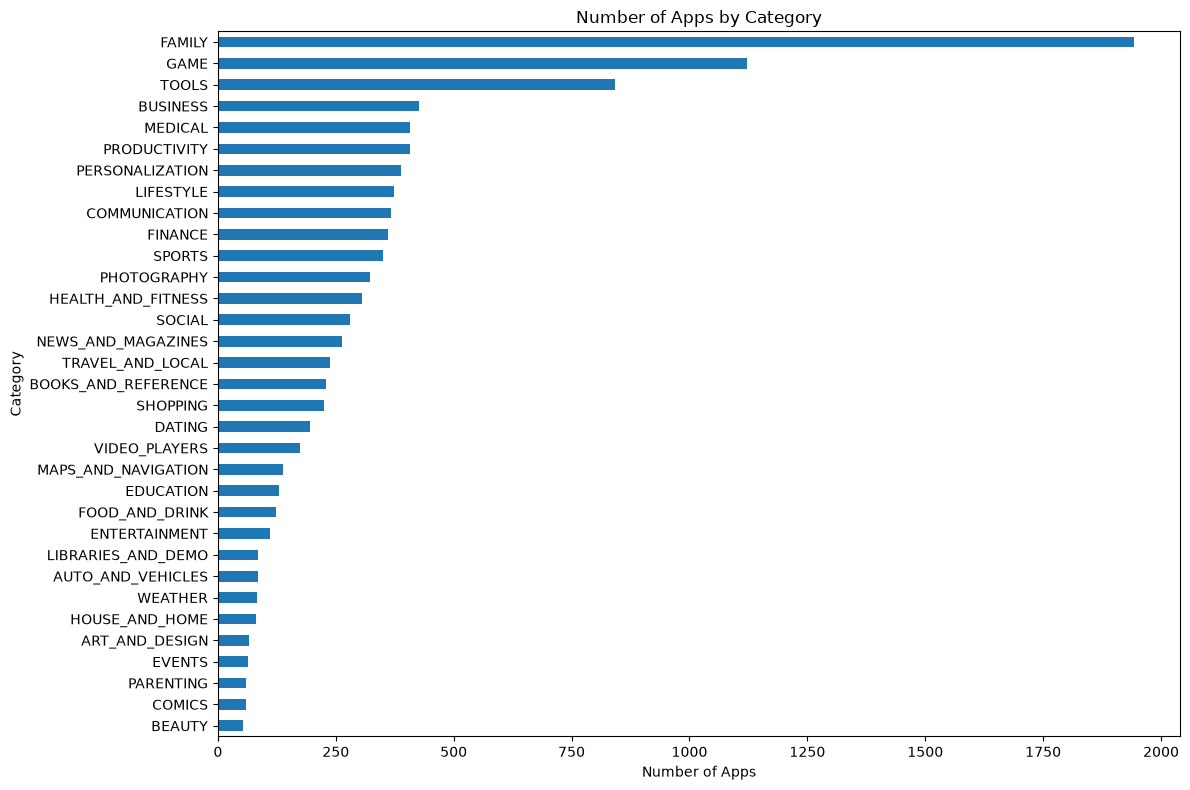

In [29]:
# Category-wise App Count

plt.figure(figsize=(12, 8))

category_counts.sort_values().plot(kind="barh")

plt.title("Number of Apps by Category")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [30]:
# Average Rating by Category

avg_rating_category = df.groupby("Category")["Rating"].mean().sort_values(ascending=False)

print(avg_rating_category)

Category
EVENTS                 4.395313
EDUCATION              4.375385
ART_AND_DESIGN         4.355385
BOOKS_AND_REFERENCE    4.336522
PERSONALIZATION        4.327062
PARENTING              4.300000
BEAUTY                 4.283019
GAME                   4.282070
HEALTH_AND_FITNESS     4.266993
SOCIAL                 4.260714
SHOPPING               4.256250
WEATHER                4.248780
SPORTS                 4.239031
PRODUCTIVITY           4.219410
MEDICAL                4.212990
LIBRARIES_AND_DEMO     4.207059
AUTO_AND_VEHICLES      4.205882
FAMILY                 4.203757
PHOTOGRAPHY            4.189441
HOUSE_AND_HOME         4.185000
FOOD_AND_DRINK         4.183871
COMMUNICATION          4.175410
BUSINESS               4.175176
NEWS_AND_MAGAZINES     4.160985
COMICS                 4.160000
FINANCE                4.148056
ENTERTAINMENT          4.136036
LIFESTYLE              4.133244
TRAVEL_AND_LOCAL       4.121941
VIDEO_PLAYERS          4.084000
TOOLS                  4.080071

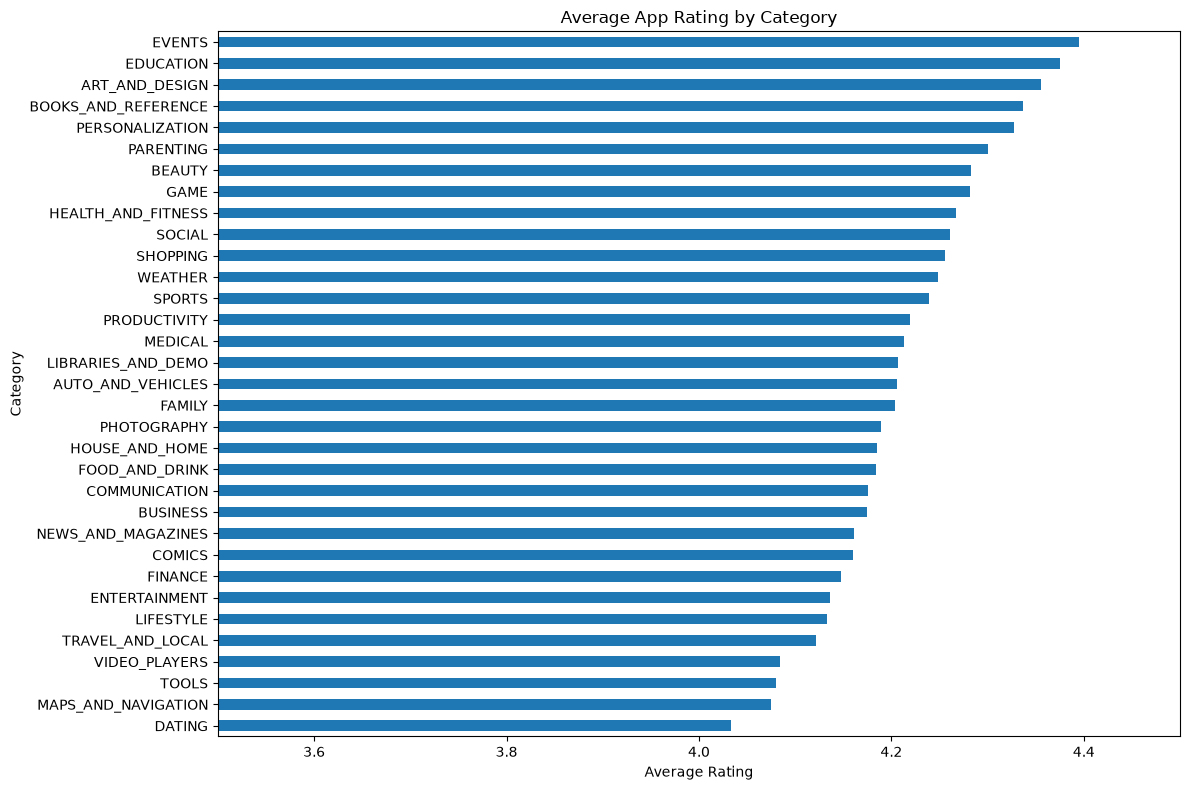

In [31]:
# Average Rating by Category

plt.figure(figsize=(12, 8))

avg_rating_category.sort_values().plot(kind="barh")

plt.title("Average App Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.xlim(3.5, 4.5)

plt.tight_layout()
plt.show()

In [32]:
# Total Installs by Category

total_installs_category = (
    df.groupby("Category")["Installs"]
    .sum()
    .sort_values(ascending=False)
)

print(total_installs_category)

Category
GAME                   31544024415
COMMUNICATION          24152276251
SOCIAL                 12513867902
PRODUCTIVITY           12463091369
TOOLS                  11452771915
FAMILY                 10041692505
PHOTOGRAPHY             9721247655
TRAVEL_AND_LOCAL        6361887146
VIDEO_PLAYERS           6222002720
NEWS_AND_MAGAZINES      5393217760
SHOPPING                2573348785
ENTERTAINMENT           2455660000
PERSONALIZATION         2074494782
BOOKS_AND_REFERENCE     1916469576
SPORTS                  1528574498
HEALTH_AND_FITNESS      1361022512
BUSINESS                 863664865
FINANCE                  770348734
MAPS_AND_NAVIGATION      724281890
LIFESTYLE                534823539
EDUCATION                533952000
WEATHER                  426100520
FOOD_AND_DRINK           257898751
DATING                   206536107
HOUSE_AND_HOME           125212461
ART_AND_DESIGN           124338100
LIBRARIES_AND_DEMO        62995910
COMICS                    56086150
AUTO_AND_VE

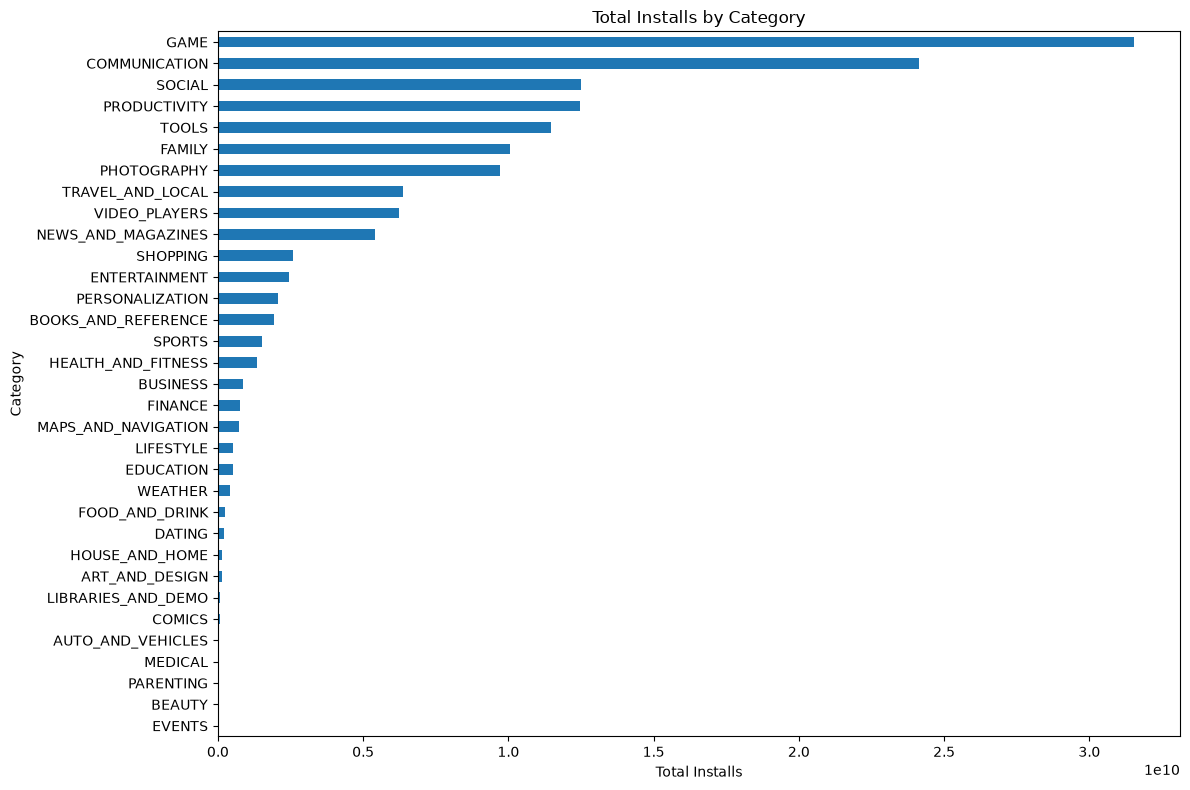

In [33]:
# Total Installs by Category

plt.figure(figsize=(12, 8))

total_installs_category.sort_values().plot(kind="barh")

plt.title("Total Installs by Category")
plt.xlabel("Total Installs")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [34]:
# Free vs Paid Apps

type_counts = df["Type"].value_counts()

print(type_counts)

Type
Free    9592
Paid     765
Name: count, dtype: int64


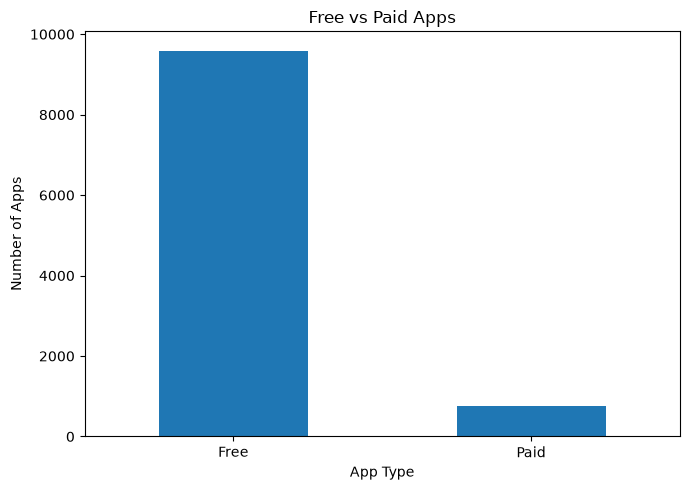

In [35]:
# Free vs Paid Apps Chart

plt.figure(figsize=(7, 5))

type_counts.plot(kind="bar")

plt.title("Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [36]:
# Average Rating of Free vs Paid Apps

avg_rating_type = df.groupby("Type")["Rating"].mean()

print(avg_rating_type)


Type
Free    4.19852
Paid    4.26915
Name: Rating, dtype: float64


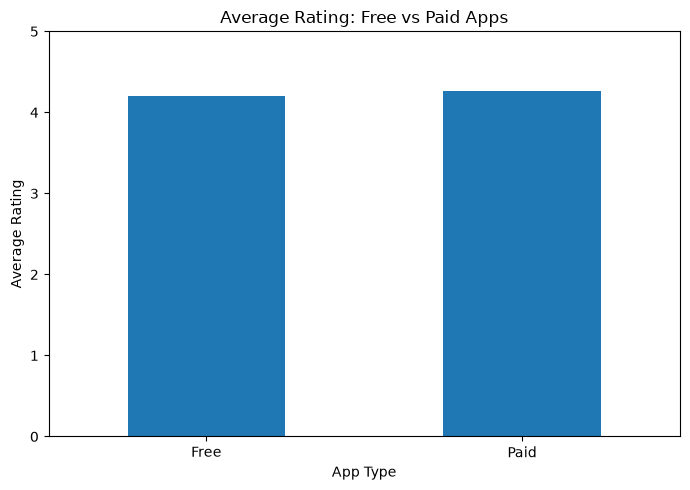

In [37]:
# Average Rating: Free vs Paid Apps

plt.figure(figsize=(7, 5))

avg_rating_type.plot(kind="bar")

plt.title("Average Rating: Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [38]:
# Top 10 Apps by Installs

top_10_apps = (
    df[["App", "Category", "Installs", "Rating"]]
    .sort_values("Installs", ascending=False)
    .head(10)
)

print(top_10_apps)

                            App            Category    Installs  Rating
3454               Google Drive        PRODUCTIVITY  1000000000     4.4
865           Google Play Games       ENTERTAINMENT  1000000000     4.3
3523               Google Drive        PRODUCTIVITY  1000000000     4.4
2544                   Facebook              SOCIAL  1000000000     4.1
2545                  Instagram              SOCIAL  1000000000     4.5
464                    Hangouts       COMMUNICATION  1000000000     4.0
3223  Maps - Navigate & Explore    TRAVEL_AND_LOCAL  1000000000     4.3
3816                Google News  NEWS_AND_MAGAZINES  1000000000     3.9
4170               Google Drive        PRODUCTIVITY  1000000000     4.4
3896             Subway Surfers                GAME  1000000000     4.5


In [39]:
# Top 10 Unique Apps by Installs

top_10_unique_apps = (
    df[["App", "Category", "Installs", "Rating"]]
    .drop_duplicates(subset="App")
    .sort_values("Installs", ascending=False)
    .head(10)
)

print(top_10_unique_apps)

                          App             Category    Installs  Rating
3736              Google News   NEWS_AND_MAGAZINES  1000000000     3.9
2554                  Google+               SOCIAL  1000000000     4.2
1654           Subway Surfers                 GAME  1000000000     4.5
152         Google Play Books  BOOKS_AND_REFERENCE  1000000000     3.9
3665                  YouTube        VIDEO_PLAYERS  1000000000     4.3
2545                Instagram               SOCIAL  1000000000     4.5
3687  Google Play Movies & TV        VIDEO_PLAYERS  1000000000     3.7
2808            Google Photos          PHOTOGRAPHY  1000000000     4.5
3127       Google Street View     TRAVEL_AND_LOCAL  1000000000     4.2
865         Google Play Games        ENTERTAINMENT  1000000000     4.3


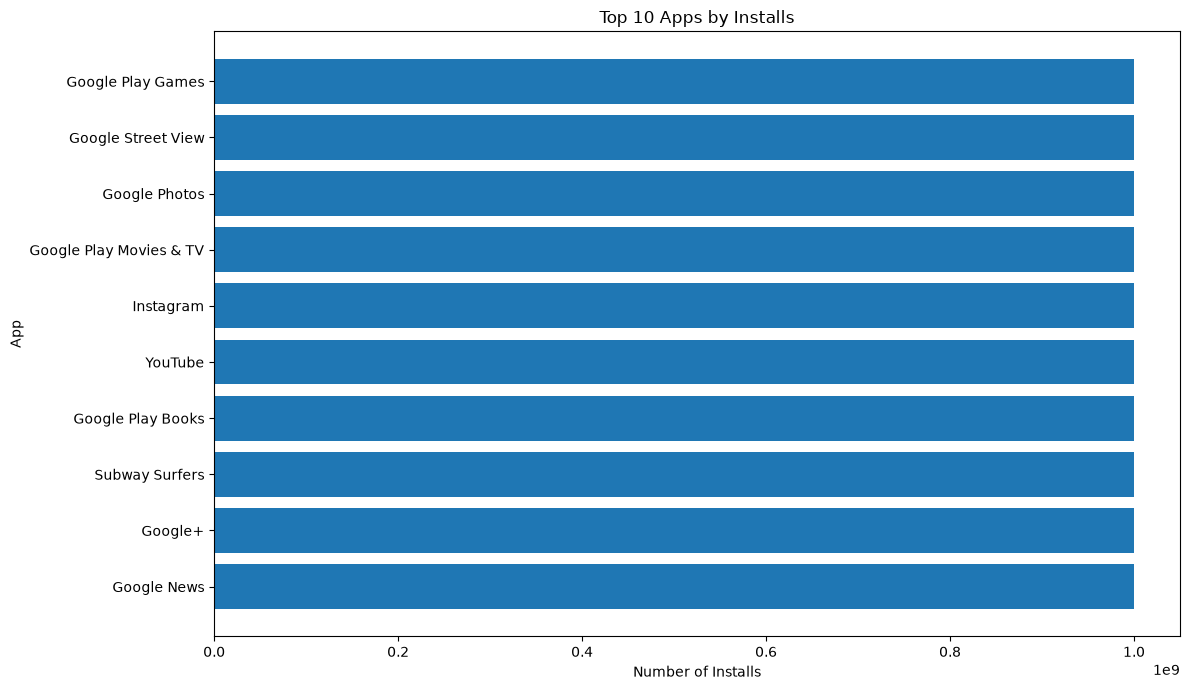

In [40]:
# Top 10 Unique Apps by Installs - Chart

plt.figure(figsize=(12, 7))

top_10_unique_apps_sorted = top_10_unique_apps.sort_values("Installs")

plt.barh(
    top_10_unique_apps_sorted["App"],
    top_10_unique_apps_sorted["Installs"]
)

plt.title("Top 10 Apps by Installs")
plt.xlabel("Number of Installs")
plt.ylabel("App")

plt.tight_layout()
plt.show()

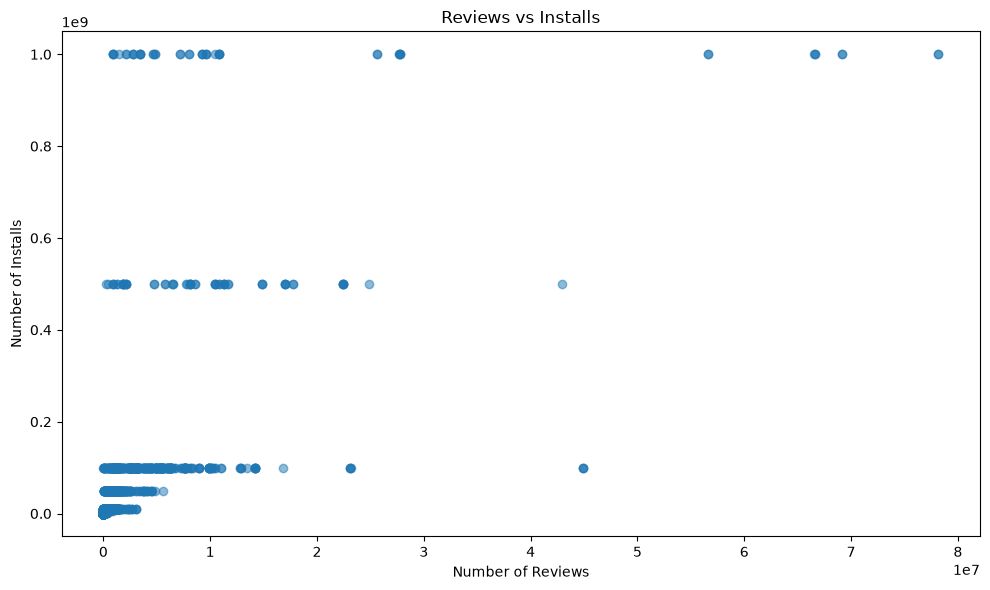

In [41]:
# Reviews vs Installs

plt.figure(figsize=(10, 6))

plt.scatter(df["Reviews"], df["Installs"], alpha=0.5)

plt.title("Reviews vs Installs")
plt.xlabel("Number of Reviews")
plt.ylabel("Number of Installs")

plt.tight_layout()
plt.show()

In [42]:
# Correlation between Reviews and Installs

correlation = df["Reviews"].corr(df["Installs"])

print("Correlation between Reviews and Installs:", correlation)

Correlation between Reviews and Installs: 0.6349973300975325


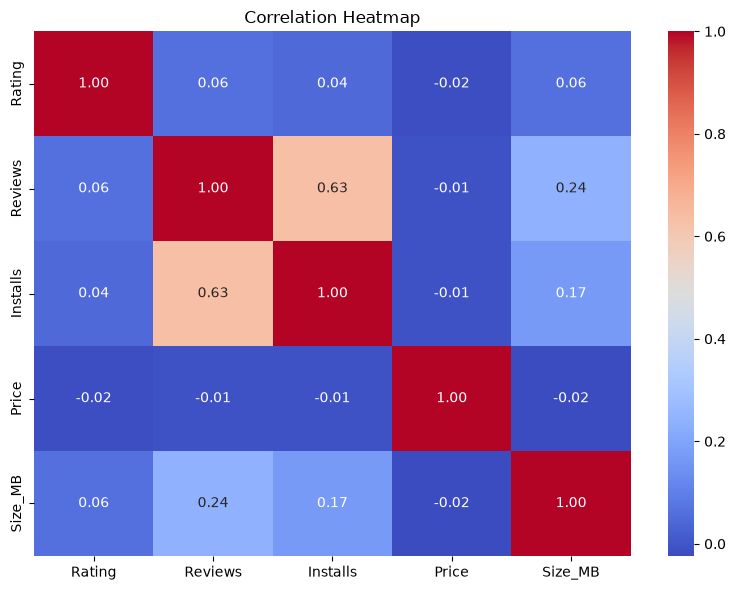

In [43]:
# Correlation Heatmap

correlation_matrix = df[
    ["Rating", "Reviews", "Installs", "Price", "Size_MB"]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [44]:
# Price Analysis of Paid Apps

paid_apps = df[df["Type"] == "Paid"].copy()

print("Number of Paid Apps:", len(paid_apps))
print("\nPrice Statistics:")
print(paid_apps["Price"].describe())

Number of Paid Apps: 765

Price Statistics:
count    765.000000
mean      13.955556
std       58.406966
min        0.990000
25%        1.490000
50%        2.990000
75%        4.990000
max      400.000000
Name: Price, dtype: float64


In [45]:
# Top 10 Most Expensive Paid Apps

top_expensive_apps = (
    paid_apps[["App", "Category", "Price", "Rating"]]
    .sort_values("Price", ascending=False)
    .head(10)
)

print(top_expensive_apps)

                                    App   Category   Price  Rating
4367           I'm Rich - Trump Edition  LIFESTYLE  400.00     3.6
5356                  I Am Rich Premium    FINANCE  399.99     4.1
5369                          I am Rich    FINANCE  399.99     4.3
5351                          I am rich  LIFESTYLE  399.99     3.8
5354                     I am Rich Plus     FAMILY  399.99     4.0
5358                         I am Rich!    FINANCE  399.99     3.8
4362                         💎 I'm rich  LIFESTYLE  399.99     3.8
4197             most expensive app (H)     FAMILY  399.99     4.3
9934  I'm Rich/Eu sou Rico/أنا غني/我很有錢  LIFESTYLE  399.99     4.3
5373                 I AM RICH PRO PLUS    FINANCE  399.99     4.0


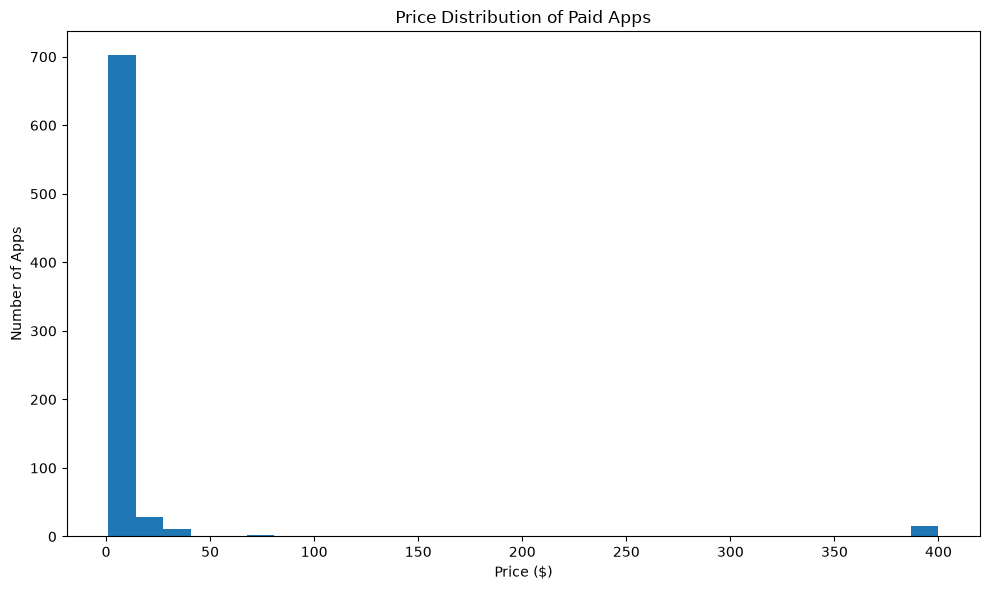

In [46]:
# Price Distribution of Paid Apps

plt.figure(figsize=(10, 6))

plt.hist(paid_apps["Price"], bins=30)

plt.title("Price Distribution of Paid Apps")
plt.xlabel("Price ($)")
plt.ylabel("Number of Apps")

plt.tight_layout()
plt.show()


In [48]:
# Category Performance Summary

category_summary = df.groupby("Category").agg(
    App_Count=("App", "count"),
    Average_Rating=("Rating", "mean"),
    Total_Installs=("Installs", "sum")
).sort_values("Total_Installs", ascending=False)

print(category_summary)

                     App_Count  Average_Rating  Total_Installs
Category                                                      
GAME                      1121        4.282070     31544024415
COMMUNICATION              366        4.175410     24152276251
SOCIAL                     280        4.260714     12513867902
PRODUCTIVITY               407        4.219410     12463091369
TOOLS                      843        4.080071     11452771915
FAMILY                    1943        4.203757     10041692505
PHOTOGRAPHY                322        4.189441      9721247655
TRAVEL_AND_LOCAL           237        4.121941      6361887146
VIDEO_PLAYERS              175        4.084000      6222002720
NEWS_AND_MAGAZINES         264        4.160985      5393217760
SHOPPING                   224        4.256250      2573348785
ENTERTAINMENT              111        4.136036      2455660000
PERSONALIZATION            388        4.327062      2074494782
BOOKS_AND_REFERENCE        230        4.336522      191

## Key Insights

1. **Category Distribution:**
   The FAMILY category has the highest number of apps with 1,943 apps, followed by GAME with 1,121 apps and TOOLS with 843 apps.

2. **App Ratings:**
   The EVENTS category has the highest average rating of approximately 4.40, followed by EDUCATION with approximately 4.38. The DATING category has the lowest average rating at approximately 4.03.

3. **Total Installs:**
   GAME has the highest total number of installs at approximately 31.54 billion, followed by COMMUNICATION with approximately 24.15 billion installs.

4. **Free vs Paid Apps:**
   The dataset contains 9,592 free apps and 765 paid apps, showing that free apps are much more common than paid apps.

5. **Free vs Paid Ratings:**
   Paid apps have a slightly higher average rating (4.27) compared with free apps (4.20).

6. **Reviews and Installs:**
   Reviews and installs have a correlation of approximately 0.635, indicating a moderate positive relationship. Apps with higher installs generally tend to receive more reviews.

7. **Top Installed Apps:**
   Several popular apps such as Google News, YouTube, Instagram, Google Photos, Subway Surfers, and Google Play Games have approximately 1 billion installs in the dataset.

8. **Price Analysis:**
   Most apps are free, while paid apps have a wide range of prices. A small number of unusually expensive apps have prices close to $400.


## Conclusion

The Google Play Store dataset was cleaned and analyzed to understand app categories, ratings, installs, reviews, pricing, and other important factors.

The analysis shows that the **FAMILY** category has the highest number of apps, while **GAME** has the highest total number of installs. The **EVENTS** category has the highest average rating, but it has relatively fewer installs, showing that a high rating does not always mean high popularity.

Free apps are much more common than paid apps. Paid apps have a slightly higher average rating than free apps. The correlation between reviews and installs is approximately **0.635**, indicating a moderate positive relationship between user reviews and app popularity.

### Recommendations

1. Developers can focus on high-demand categories such as **GAME, COMMUNICATION, SOCIAL, and PRODUCTIVITY**, while keeping competition in mind.

2. A **free or freemium pricing model** can help reach a larger number of users because free apps dominate the dataset.

3. Developers should focus on **app quality and user experience** to maintain higher ratings and positive reviews.

4. Increasing user engagement and encouraging genuine reviews may help improve app visibility and popularity.

5. Paid apps should provide clear value to users and use reasonable pricing rather than extremely high prices.


In [49]:
df.to_csv("cleaned_googleplaystore.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final Shape:", df.shape)

Cleaned dataset saved successfully!
Final Shape: (10357, 14)
